<a href="https://colab.research.google.com/github/anjeliaa/Implementasi-kasus-kuliah-praktisi-sesi-2/blob/main/implementasi_sesi2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from multiprocessing import Pool, cpu_count

In [2]:
# ==========================================
# 1. SIMULASI LINGKUNGAN AGENT-BASED BUILDING (HPC WORKLOAD)
# ==========================================
np.random.seed(42)

# Parameter Gedung Kampus
N_AGENTS = 2000       # Jumlah penghuni gedung (mahasiswa + staf)
SIM_HOURS = 24        # Durasi simulasi (24 Jam)

# Kategori Kebijakan Energi yang Diuji
POLICIES = {
    'Baseline': {'ac_temp': 20, 'max_hour': 22, 'policy_strictness': 0.1},
    'Energy_Saving_A': {'ac_temp': 24, 'max_hour': 20, 'policy_strictness': 0.6},
    'Strict_Green_B': {'ac_temp': 25, 'max_hour': 18, 'policy_strictness': 0.9}
}

def simulate_agent_behavior(args):
    agent_id, policy_name, policy_params = args
    np.random.seed(agent_id + int(time.time() * 1000) % 100000)

    hourly_kwh = []
    # Profil kehadiran agen (Jam 08:00 - 18:00 puncak aktivitas)
    presence_probability = np.sin(np.linspace(0, np.pi, 24)) ** 2

    for hour in range(SIM_HOURS):
        is_present = np.random.rand() < presence_probability[hour]

        if is_present and hour < policy_params['max_hour']:
            # Penggunaan Listrik Dasar AC + Peralatan per Agen (kWh)
            base_power = (30 - policy_params['ac_temp']) * 0.15
            # Kepatuhan terhadap Kebijakan Listrik
            compliance = np.random.rand() < policy_params['policy_strictness']

            if compliance:
                power_used = base_power * 0.7  # Hemat daya jika patuh
            else:
                power_used = base_power * 1.2  # Boros jika tidak patuh
        else:
            power_used = 0.02  # Standby power gedung

        hourly_kwh.append(power_used)

    return hourly_kwh

In [3]:
# ==========================================
# 2. EKSEKUSI SIMULASI SIMULTAN BEBAN HPC (PARALLEL COMPUTING)
# ==========================================
if __name__ == '__main__':
    print(f"=== MENJALANKAN SIMULASI HPC DENGAN {cpu_count()} CPU CORES ===")

    simulation_results = {}
    execution_times = {}

    for p_name, p_params in POLICIES.items():
        start_time = time.time()

        # Penyiapan Beban Komputasi Paralel
        task_args = [(i, p_name, p_params) for i in range(N_AGENTS)]

        with Pool(processes=cpu_count()) as pool:
            results = pool.map(simulate_agent_behavior, task_args)

        exec_time = time.time() - start_time
        execution_times[p_name] = exec_time

        # Aggregasi Total kWh Gedung per Jam
        hourly_total = np.sum(results, axis=0)
        simulation_results[p_name] = hourly_total

        print(f"Kebijakan: {p_name:15s} | Selesai dalam {exec_time:.4f} detik | Total Konsumsi: {np.sum(hourly_total):.2f} kWh")

=== MENJALANKAN SIMULASI HPC DENGAN 2 CPU CORES ===
Kebijakan: Baseline        | Selesai dalam 0.1395 detik | Total Konsumsi: 40348.70 kWh
Kebijakan: Energy_Saving_A | Selesai dalam 0.1444 detik | Total Konsumsi: 18796.80 kWh
Kebijakan: Strict_Green_B  | Selesai dalam 0.1351 detik | Total Konsumsi: 12462.40 kWh


/tmp/ipykernel_1467/932988350.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=total_kwh.index, y=total_kwh.values, palette='viridis')


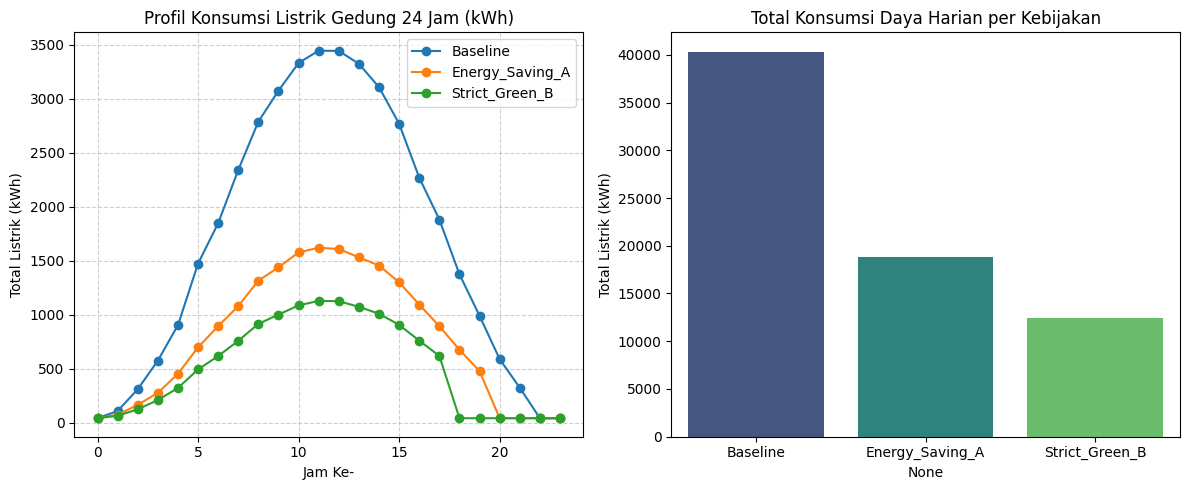

In [7]:
    # ==========================================
    # 3. VISUALISASI PERBANDINGAN EFFISIENSI ENERGI (RATA KIRI SEJAJAR DENGAN FOR)
    # ==========================================
    df_results = pd.DataFrame(simulation_results)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    for col in df_results.columns:
        plt.plot(range(SIM_HOURS), df_results[col], marker='o', label=col)
    plt.title('Profil Konsumsi Listrik Gedung 24 Jam (kWh)')
    plt.xlabel('Jam Ke-')
    plt.ylabel('Total Listrik (kWh)')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()

    plt.subplot(1, 2, 2)
    total_kwh = df_results.sum()
    sns.barplot(x=total_kwh.index, y=total_kwh.values, palette='viridis')
    plt.title('Total Konsumsi Daya Harian per Kebijakan')
    plt.ylabel('Total Listrik (kWh)')
    plt.tight_layout()
    plt.show()